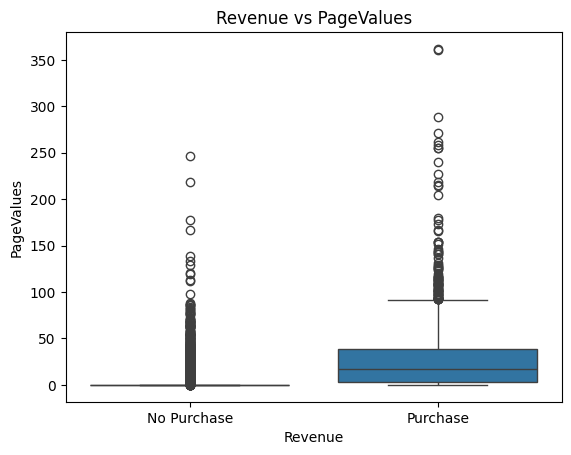

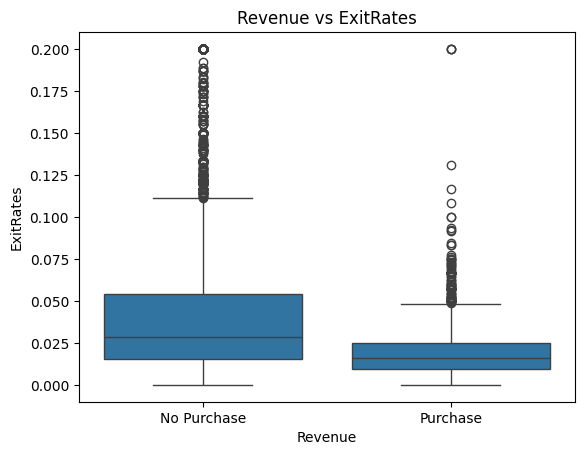

In [12]:
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns

#Load Data
online_shoppers_df=pd.read_csv('online_shoppers_intention.csv')

#Question 1
#Plot 1: PageValues
sns.boxplot(data=online_shoppers_df, x='Revenue', y='PageValues')
plt.title('Revenue vs PageValues')
plt.xlabel('Revenue')
plt.ylabel('PageValues')
plt.show()

#Plot 2: ExitRates
sns.boxplot(data=online_shoppers_df, x='Revenue', y='ExitRates')
plt.title('Revenue vs ExitRates')
plt.xlabel('Revenue')
plt.ylabel('ExitRates')
plt.show()

# PageValues is the better predictor and cleanely seperates purchases and non purchases sessions.
# Non-purchasing sessions usually have a PageValue of zero, while purchasing sessions show much higher values.
# ExitRates overlap too much. Both buyers and non-buyers show similar exit rate ranges, making ExitRates a weak predictor.
# Retail managers can monitor PageValues to spot serious buyers early.


In [13]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

#Question 2
shoppers_X = online_shoppers_df[ ['Administrative', 'Informational', 'ProductRelated', 'ProductRelated_Duration', 'ExitRates', 'PageValues'] ]
shoppers_y = online_shoppers_df['Revenue']

# Partition data (70% training, 30% testing, random state=2)
X_train, X_test, y_train, y_test = train_test_split(shoppers_X,shoppers_y, test_size=0.3, random_state=2)

# Fit classification tree (max depth=3, random state=20)
shoppers_tree = DecisionTreeClassifier(max_depth=3, random_state=20)
shoppers_tree.fit(X_train, y_train)

print("Training set size :", X_train.shape[0])
print("Testing set size :", X_test.shape[0])

Training set size : 8631
Testing set size : 3699


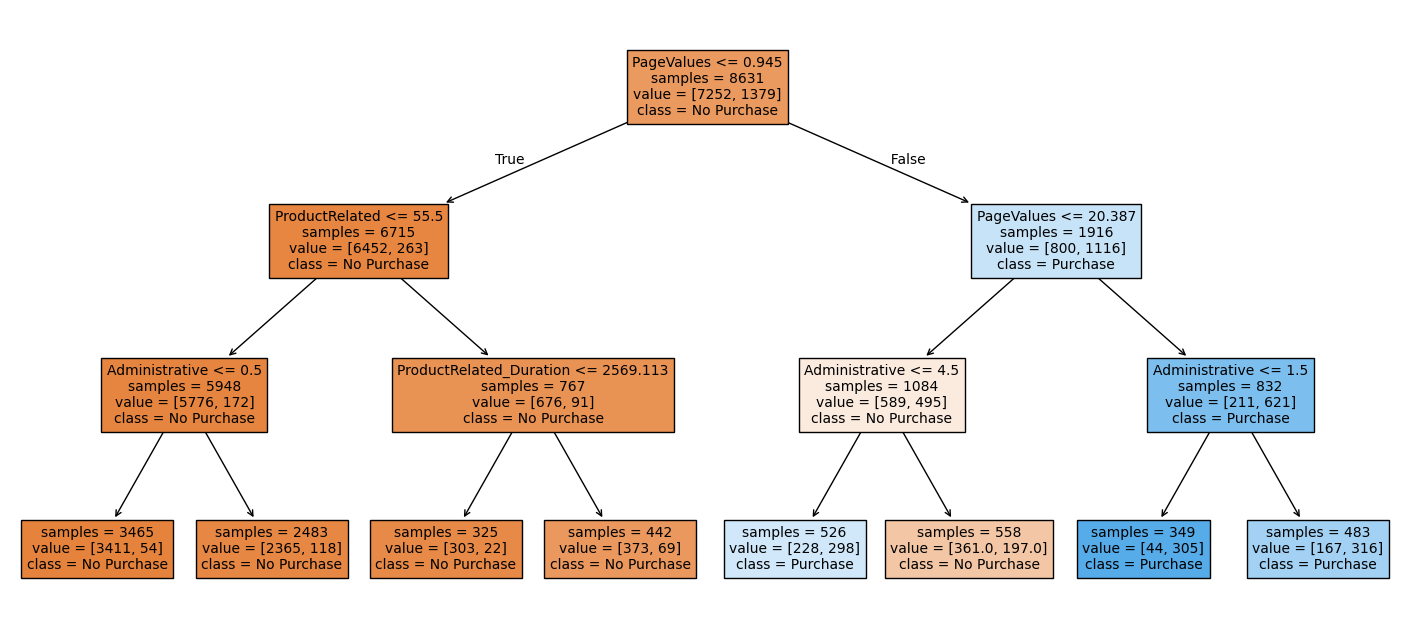

In [14]:
from sklearn.tree import plot_tree

# Question 3: Visualize the Fitted Decision Tree
plt.figure(figsize=(18, 8))
plot_tree(
    shoppers_tree,
    feature_names=shoppers_X.columns,
    class_names=shoppers_tree.classes_,
    filled=True,
    impurity=False,
    fontsize=10
)
plt.show()

# The three most impactful predictors are PageValues, Administrative, and ProductRelated.
# PageValues is the root split and is a primary driver for separating buyers from non-buyers. It carries 94% of the total feature importance.
# Administrative is the second most important, checking if a user visits account or admin pages to help confirm if they are really going to buy.
# ProductRelated is the 3rd important predictor, using how many product pages a user views to help tell serious shoppers apart from casual window-shoppers.

In [15]:
# Question 4: Predict for New Session

new_session = pd.DataFrame([{
    'Administrative' : 6,
    'Informational' : 2,
    'ProductRelated' : 75,
    'ProductRelated_Duration': 3500,
    'ExitRates': 0.008,
    'PageValues': 50.0
}])

new_prediction = shoppers_tree.predict(new_session)[0]
print("Prediction for new session:", new_prediction)

# The tree predicts Purchase. The session's PageValues of 50 falls above both PageValues thresholds in the tree (0.94 and 20.39).
# It has more than 1.5 Administrative page visits (6). The predicted probability is about 65%.

Prediction for new session: Purchase


In [16]:
from sklearn.metrics import accuracy_score

# Question 5: Accuracy Evaluation

train_acc = shoppers_tree.score(X_train, y_train)
test_acc = shoppers_tree.score(X_test, y_test)
print("Training set accuracy:", train_acc)
print("Testing set accuracy:", test_acc)

baseline_pred =['No Purchase'] * len(y_test)
baseline_acc = accuracy_score(y_test, baseline_pred)
print("Baseline accuracy:", baseline_acc)

# The decision tree achieves a test accuracy of 88.59%, which is 2.89% higher than the baseline accuracy of 85.70%.
# The baseline accuracy is 85.7% simply because most visitors don't buy anything.
# While the tree's test accuracy is only 2.9% higher, it is much more useful because the baseline finds zero buyers, while the tree actually identifies real shoppers.
# Metrics like precision and recall are better ways to evaluate this model, and the small gap between train and test scores shows the tree is not overfitting.

Training set accuracy: 0.8958405746726915
Testing set accuracy: 0.8859151121924844
Baseline accuracy: 0.8569883752365505
